# Airline Flight Delay Prediction

**Prepared by:**

| Student Name | Student ID |
|---|---|
| Reem Alwegdani | 2323653 |
| Shahad Banakher | 2305945 |
| Jory Alsufyani | 2306407 |
| Reem Alzahrani | 2307042 |
**Section:** DAR

## Project Overview

This project examines historical airline flight data to support the prediction of whether a flight will arrive delayed or on time. The dataset includes flight schedules, departure and arrival delays, flight duration, distance, and airline and airport information. This notebook focuses on the initial data exploration: examining the datasets, identifying missing values and attribute types, visualizing flight delays, and studying correlations between numerical attributes. The classification target and prediction model will be developed in a later phase.


## Dataset Loading
Load the flight, airport, and airline datasets and check their dimensions.

In [33]:
import numpy as np
import pandas as pd
import kagglehub
import os
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix

# Download the dataset
path = kagglehub.dataset_download("usdot/flight-delays")

# Load the three CSV files
airports = pd.read_csv(os.path.join(path, "airports.csv"))
flights = pd.read_csv(os.path.join(path, "flights.csv"), low_memory=False)
airlines = pd.read_csv(os.path.join(path, "airlines.csv"))

datasets = {
    "Airports": airports,
    "Flights": flights,
    "Airlines": airlines
}

print("Airports:", airports.shape)
print("Flights:", flights.shape)
print("Airlines:", airlines.shape)

Airports: (322, 7)
Flights: (5819079, 31)
Airlines: (14, 2)


## 1. Dataset Inspection
Display the first and last five records of each dataset.

In [34]:
# Question 1: Display head and tail
for name, data in datasets.items():
    print(f"\nFirst 5 rows of {name}:")
    display(data.head())

    print(f"\nLast 5 rows of {name}:")
    display(data.tail())


First 5 rows of Airports:


,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
0,ABE,Lehigh Valley International Airport,Allentown,PA,USA,40.65236,-75.44040
1,ABI,Abilene Regional Airport,Abilene,TX,USA,32.41132,-99.68190
2,ABQ,Albuquerque International Sunport,Albuquerque,NM,USA,35.04022,-106.60919
3,ABR,Aberdeen Regional Airport,Aberdeen,SD,USA,45.44906,-98.42183
4,ABY,Southwest Georgia Regional Airport,Albany,GA,USA,31.53552,-84.19447



Last 5 rows of Airports:


,IATA_CODE,AIRPORT,CITY,STATE,COUNTRY,LATITUDE,LONGITUDE
317,WRG,Wrangell Airport,Wrangell,AK,USA,56.48433,-132.36982
318,WYS,Westerly State Airport,West Yellowstone,MT,USA,44.68840,-111.11764
319,XNA,Northwest Arkansas Regional Airport,Fayetteville/Springdale/Rogers,AR,USA,36.28187,-94.30681
320,YAK,Yakutat Airport,Yakutat,AK,USA,59.50336,-139.66023
321,YUM,Yuma International Airport,Yuma,AZ,USA,32.65658,-114.60597



First 5 rows of Flights:


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


... (2 outputs left out)


First 5 rows of Airlines:


,IATA_CODE,AIRLINE
0,UA,United Air Lines Inc.
1,AA,American Airlines Inc.
2,US,US Airways Inc.
3,F9,Frontier Airlines Inc.
4,B6,JetBlue Airways



Last 5 rows of Airlines:


,IATA_CODE,AIRLINE
9,DL,Delta Air Lines Inc.
10,EV,Atlantic Southeast Airlines
11,HA,Hawaiian Airlines Inc.
12,MQ,American Eagle Airlines Inc.
13,VX,Virgin America


## 2. Dataset Description
### 2a. Number of Instances and Attributes
Count the records and attributes in each dataset.

In [35]:
# 2a. Number of instances and attributes
# Instances are rows, and attributes are columns.
for name, data in datasets.items():
    print(f"\n{name}")
    print("Number of instances:", data.shape[0])
    print("Number of attributes:", data.shape[1])


Airports
Number of instances: 322
Number of attributes: 7

Flights
Number of instances: 5819079
Number of attributes: 31

Airlines
Number of instances: 14
Number of attributes: 2


### 2b. Missing Values
Count missing values overall and for each attribute.

In [36]:
# 2b. Missing values
for name, data in datasets.items():
    print(f"\n{name}")
    print("Total missing values:", data.isnull().sum().sum())
    print("\nMissing values per attribute:")
    display(data.isnull().sum().to_frame("Missing Values"))


Airports
Total missing values: 6

Missing values per attribute:


,Missing Values
IATA_CODE,0
AIRPORT,0
CITY,0
STATE,0
COUNTRY,0
LATITUDE,3
LONGITUDE,3



Flights
Total missing values: 30465274

Missing values per attribute:


,Missing Values
YEAR,0
MONTH,0
DAY,0
DAY_OF_WEEK,0
AIRLINE,0
FLIGHT_NUMBER,0
TAIL_NUMBER,14721
ORIGIN_AIRPORT,0
DESTINATION_AIRPORT,0
SCHEDULED_DEPARTURE,0



Airlines
Total missing values: 0

Missing values per attribute:


,Missing Values
IATA_CODE,0
AIRLINE,0


### 2c. Missing-Value Representation
Check for `NaN` values and placeholder strings such as `unknown` or `?`.

In [37]:
# 2c. Missing-value representation
for name, data in datasets.items():
    print(f"\n{name}")
    print("NaN values:", data.isna().sum().sum())

    for col in data.select_dtypes(include=["object", "str"]).columns:
        values = data[col].astype("string").str.strip().str.lower()
        special = values.isin(["unknown", "?"]).sum()

        if special > 0:
            print(f"{col}: {special} values represented as 'unknown' or '?'")


Airports
NaN values: 6

Flights
NaN values: 30465274

Airlines
NaN values: 0


### 2d. Attribute Data Types
Identify numerical and text attributes in each dataset.

In [38]:
# 2d. Data types
for name, data in datasets.items():
    print(f"\n{name}")
    print(data.dtypes)
    print("Numerical:", data.select_dtypes(include=np.number).columns.tolist())
    print("String   :", data.select_dtypes(include=["object", "str"]).columns.tolist())


Airports
IATA_CODE        str
AIRPORT          str
CITY             str
STATE            str
COUNTRY          str
LATITUDE     float64
LONGITUDE    float64
dtype: object
Numerical: ['LATITUDE', 'LONGITUDE']
String   : ['IATA_CODE', 'AIRPORT', 'CITY', 'STATE', 'COUNTRY']

Flights
YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                    str
FLIGHT_NUMBER            int64
TAIL_NUMBER                str
ORIGIN_AIRPORT             str
DESTINATION_AIRPORT        str
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME         float64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERT

### 2e. Categorical Attributes
List categories for attributes with up to 30 distinct values; show the five most frequent values for higher-cardinality attributes.

In [39]:
# 2e. Categorical attributes and categories
for name, data in datasets.items():
    print(f"\n===== {name} =====")
    for col in data.select_dtypes(include=["object", "str"]).columns:
        n = data[col].nunique()
        print(f"\n{col}: {n} categories")
        if n <= 30:
            print(data[col].dropna().unique())
        else:
            print("Too many to list. Top 5:")
            print(data[col].value_counts().head(5))


===== Airports =====

IATA_CODE: 322 categories
Too many to list. Top 5:
IATA_CODE
ABE    1
ABI    1
ABQ    1
ABR    1
ABY    1
Name: count, dtype: int64

AIRPORT: 322 categories
Too many to list. Top 5:
AIRPORT
Lehigh Valley International Airport    1
Abilene Regional Airport               1
Albuquerque International Sunport      1
Aberdeen Regional Airport              1
Southwest Georgia Regional Airport     1
Name: count, dtype: int64

CITY: 308 categories
Too many to list. Top 5:
CITY
Albany        2
Columbia      2
Charleston    2
San Diego     2
Columbus      2
Name: count, dtype: int64

STATE: 54 categories
Too many to list. Top 5:
STATE
TX    24
CA    22
AK    19
FL    17
MI    15
Name: count, dtype: int64

COUNTRY: 1 categories
<ArrowStringArray>
['USA']
Length: 1, dtype: str

===== Flights =====

AIRLINE: 14 categories
<ArrowStringArray>
['AS', 'AA', 'US', 'DL', 'NK', 'UA', 'HA', 'B6', 'OO', 'EV', 'MQ', 'F9', 'WN',
 'VX']
Length: 14, dtype: str

TAIL_NUMBER: 4897 categories

## 3. Data Visualization


### 3a. Histogram — Flight Delay Distributions

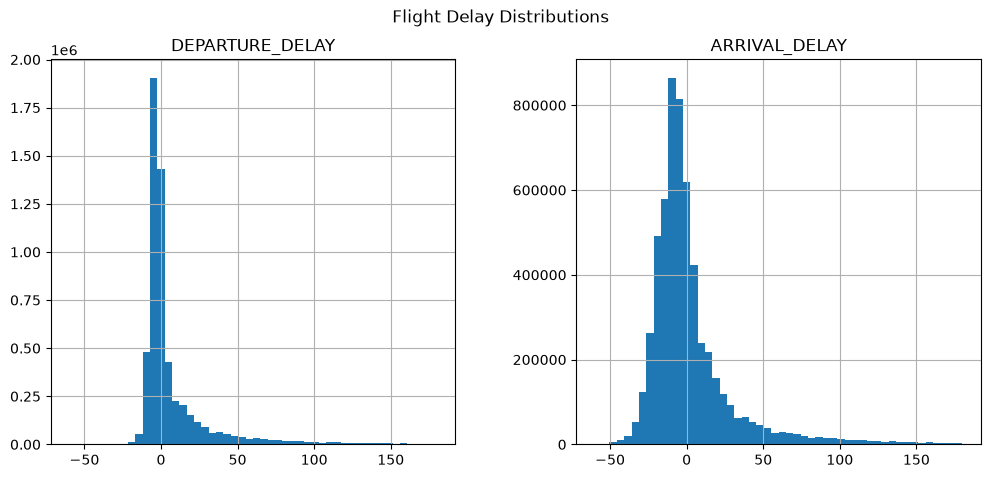

In [45]:
# Plot histograms for departure and arrival delays
flights.hist(
    column=["DEPARTURE_DELAY", "ARRIVAL_DELAY"],
    bins=50,
    figsize=(12, 5),
    range=(-60, 180)
)

# Add a title and display the plots
plt.suptitle("Flight Delay Distributions")
plt.show()

The histograms show that most flights have relatively small departure and arrival delays, while fewer flights experience longer delays. Both distributions are right-skewed, indicating that some flights experience significantly longer delays than the majority.

### 3b. Boxplots — Departure and Arrival Delays

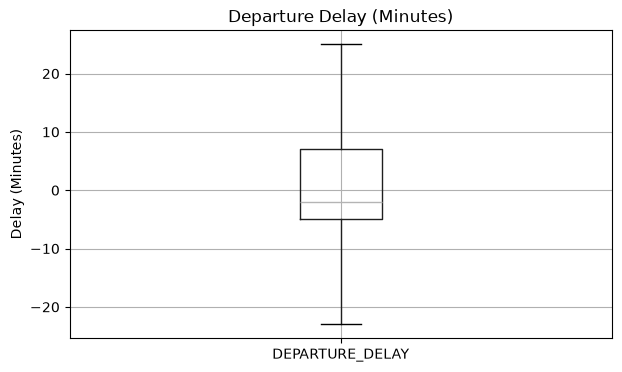

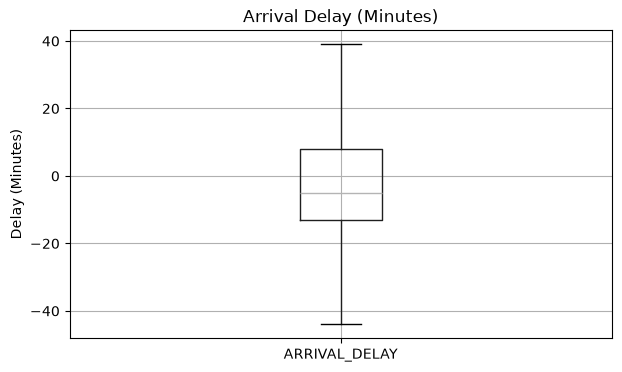

In [47]:
# Plot a boxplot for departure delays
flights.boxplot(
    column="DEPARTURE_DELAY",
    figsize=(7, 4),
    showfliers=False
)

plt.title("Departure Delay (Minutes)")
plt.ylabel("Delay (Minutes)")
plt.show()

# Plot a boxplot for arrival delays
flights.boxplot(
    column="ARRIVAL_DELAY",
    figsize=(7, 4),
    showfliers=False
)

plt.title("Arrival Delay (Minutes)")
plt.ylabel("Delay (Minutes)")
plt.show()

The boxplots show the central distribution and variability of departure and arrival delays. The median values and interquartile ranges help compare typical delays and their spread. Extreme values are not displayed because outlier markers have been hidden, allowing the central distributions to be examined more clearly.

### 3c. Scatter Plot — Departure Delay vs. Arrival Delay

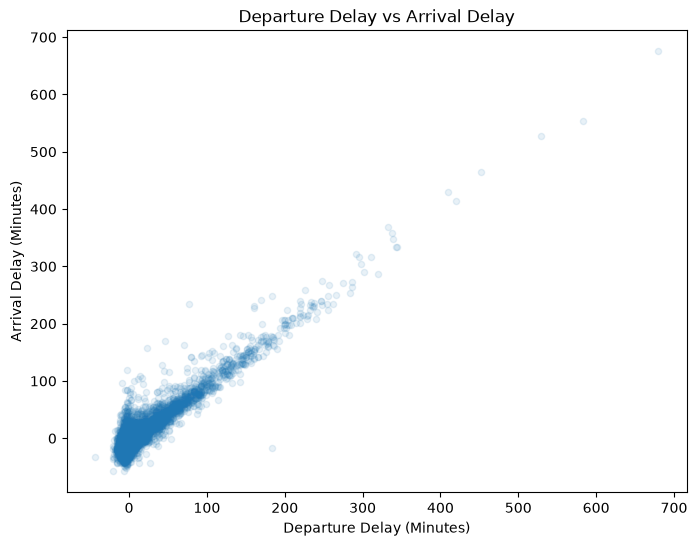

In [48]:
# Select departure and arrival delays and remove missing values
# Use a random sample to improve visualization performance
flight_sample = flights[
    ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]
].dropna().sample(
    n=10000,
    random_state=42
)

# Plot the relationship between departure and arrival delays
flight_sample.plot(
    kind="scatter",
    x="DEPARTURE_DELAY",
    y="ARRIVAL_DELAY",
    alpha=0.1,
    figsize=(8, 6)
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")
plt.show()

The scatter plot shows a strong positive relationship between departure and arrival delays. Flights with longer departure delays generally experience longer arrival delays. However, some flights may recover or accumulate additional delays during the journey.

## 4. Correlation Between Attributes


### 4a. Pearson Correlation Matrix

,DEPARTURE_DELAY,ARRIVAL_DELAY,AIR_TIME,DISTANCE,TAXI_OUT,TAXI_IN,SCHEDULED_TIME,ELAPSED_TIME
DEPARTURE_DELAY,1.000000,0.944672,0.023495,0.024106,0.058515,0.012784,0.027799,0.030805
ARRIVAL_DELAY,0.944672,1.000000,-0.007108,-0.025444,0.227319,0.116628,-0.030029,0.029120
AIR_TIME,0.023495,-0.007108,1.000000,0.985643,0.087608,0.082292,0.990749,0.990033
DISTANCE,0.024106,-0.025444,0.985643,1.000000,0.072333,0.075232,0.984336,0.973696
TAXI_OUT,0.058515,0.227319,0.087608,0.072333,1.000000,0.003221,0.112302,0.205195
TAXI_IN,0.012784,0.116628,0.082292,0.075232,0.003221,1.000000,0.099036,0.156179
SCHEDULED_TIME,0.027799,-0.030029,0.990749,0.984336,0.112302,0.099036,1.000000,0.985260
ELAPSED_TIME,0.030805,0.029120,0.990033,0.973696,0.205195,0.156179,0.985260,1.000000


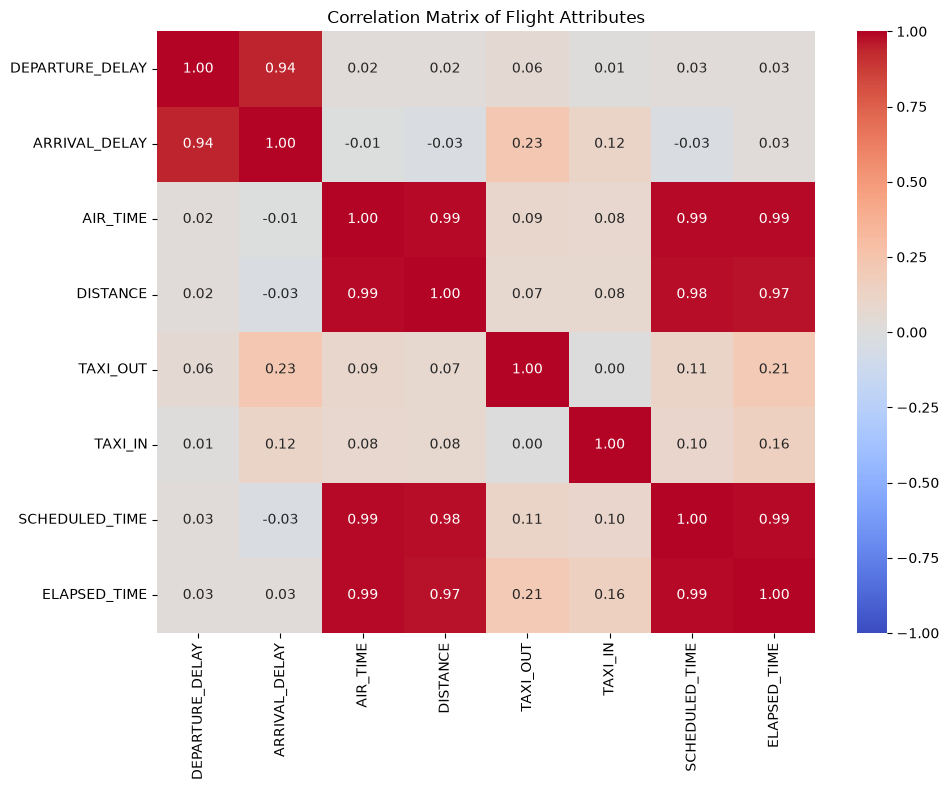

Correlation with ARRIVAL_DELAY:


ARRIVAL_DELAY      1.000000
DEPARTURE_DELAY    0.944672
TAXI_OUT           0.227319
TAXI_IN            0.116628
ELAPSED_TIME       0.029120
AIR_TIME          -0.007108
DISTANCE          -0.025444
SCHEDULED_TIME    -0.030029
Name: ARRIVAL_DELAY, dtype: float64

In [44]:
# Pearson correlation between relevant numerical flight attributes
attributes = [
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "AIR_TIME",
    "DISTANCE",
    "TAXI_OUT",
    "TAXI_IN",
    "SCHEDULED_TIME",
    "ELAPSED_TIME"
]

corr_matrix = flights[attributes].corr(
    numeric_only=True
)

display(corr_matrix)

# Correlation matrix visualization
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Flight Attributes")
plt.tight_layout()
plt.show()

print("Correlation with ARRIVAL_DELAY:")

display(
    corr_matrix["ARRIVAL_DELAY"]
    .sort_values(ascending=False)
)

The correlation matrix shows a very strong positive relationship between departure delay and arrival delay (0.9447), indicating that flights departing late generally tend to arrive late. Air time and distance also have a very strong positive correlation (0.9856). Taxi-out time has a weak positive correlation with arrival delay (0.2273), while distance (-0.0254) and scheduled time (-0.0300) have very weak negative correlations with arrival delay. Correlation measures linear relationships and does not imply causation.